# Well Log Analysis — Shale Volume and Log Quality

Well log data from a 192 m interval. Four steps:

1. Use a gamma ray histogram to pick the clean and shale values from the data
2. Calculate shale volume from those values
3. Plot all five curves, including the density correction curve
4. Count how much of the well is sand

**Curves:** DEPTH (m), GR (gamma ray, API), DT (sonic, us/ft), RHOB (density, g/cc),
DRHO (density correction, g/cc), NPHI (neutron porosity, v/v).

## Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

well = pd.read_csv("WellData.csv")

# -999.25 and -999 are null placeholders. Left in, they ruin averages and plot scales.
well = well.replace([-999.25, -999.0], np.nan)

print(f"{len(well)} rows, {well['DEPTH'].min():.1f} to {well['DEPTH'].max():.1f} m")
well.head()

1921 rows, 4609.8 to 4801.8 m


,DEPTH,GR,DT,RHOB,DRHO,NPHI
0,4609.8008,89.059479,NaN,2.483700,0.018494,0.129119
1,4609.9008,90.721848,NaN,2.489308,0.013656,0.108034
2,4610.0008,90.709061,NaN,2.501088,0.011289,0.085650
3,4610.1008,89.568954,66.223099,2.515450,0.008615,0.070332
4,4610.2008,88.169571,66.705551,2.530982,0.005628,0.065343


In [2]:
well.describe().round(3)

,DEPTH,GR,DT,RHOB,DRHO,NPHI
count,1921.000,1921.000,1918.000,1921.000,1921.000,1921.000
mean,4705.800,67.544,67.398,2.554,0.020,0.114
std,55.469,31.456,4.525,0.121,0.045,0.039
min,4609.801,19.606,54.929,1.947,-0.132,0.033
25%,4657.801,38.903,64.325,2.495,-0.013,0.092
50%,4705.800,63.488,67.393,2.558,0.007,0.111
75%,4753.800,95.923,70.078,2.647,0.055,0.129
max,4801.800,137.463,89.621,2.789,0.134,0.417


Sampling is every 0.1 m. Only DT has gaps (3 samples), so the data is essentially complete.

## 1. Picking the clean and shale values

Gamma ray measures natural radioactivity. Clay minerals contain potassium and
absorb thorium and uranium, so shale reads high. Clean quartz sand reads low.

A histogram shows the two groups directly, so the cutoff comes from the data
instead of being guessed.

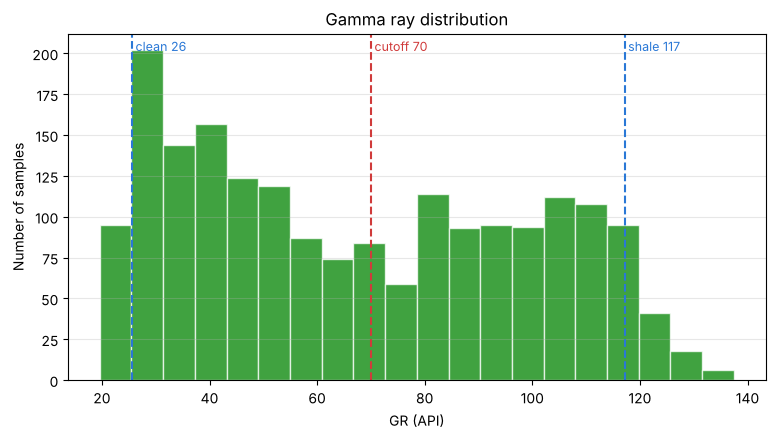

In [3]:
gr = well["GR"].dropna()

# 5th and 95th percentile instead of min and max, so one odd reading
# cannot stretch the scale.
gr_clean = gr.quantile(0.05)
gr_shale = gr.quantile(0.95)
cutoff = 70      # read off the dip between the two humps below

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(gr, bins=20, color="#008300", alpha=0.75, edgecolor="white")

for x, label, color in [(gr_clean, f"clean {gr_clean:.0f}", "#2a78d6"),
                        (cutoff,   f"cutoff {cutoff}",      "#d03b3b"),
                        (gr_shale, f"shale {gr_shale:.0f}", "#2a78d6")]:
    ax.axvline(x, color=color, ls="--", lw=1.5)
    ax.text(x, ax.get_ylim()[1] * 0.95, f" {label}", color=color, fontsize=9)

ax.set_xlabel("GR (API)")
ax.set_ylabel("Number of samples")
ax.set_title("Gamma ray distribution")
ax.grid(axis="y", alpha=0.3)
plt.show()

Two groups are visible: a sand peak near 30 API and a broader shale population
from about 80 to 120 API, with the dip between them around 70 API.

- **Clean value** — the 5th percentile, the cleanest rock in the well
- **Shale value** — the 95th percentile, the shaliest
- **Cutoff (70 API)** — the dip between the two groups, used to call sand or shale

## 2. Shale volume

Shale volume rescales gamma ray onto 0 to 1, where 0 is the cleanest rock in the
well and 1 is the shaliest:

$$V_{sh} = \frac{GR - GR_{clean}}{GR_{shale} - GR_{clean}}$$

This is the linear method — subtract the clean value, divide by the range. It
reads slightly high on shale, because gamma ray response is not perfectly
linear with clay content. Empirical corrections exist, but their coefficients
are fitted to field data rather than derived, so the straightforward version is
used here.

In [4]:
def shale_volume(gr, gr_clean, gr_shale):
    """Linear shale volume from gamma ray, clipped to 0-1."""
    vsh = (gr - gr_clean) / (gr_shale - gr_clean)
    return vsh.clip(0, 1)


well["VSH"] = shale_volume(well["GR"], gr_clean, gr_shale)

well[["DEPTH", "GR", "VSH"]].head()

,DEPTH,GR,VSH
0,4609.8008,89.059479,0.693186
1,4609.9008,90.721848,0.711341
2,4610.0008,90.709061,0.711201
3,4610.1008,89.568954,0.698750
4,4610.2008,88.169571,0.683467


In [5]:
print(f"Average shale volume: {well['VSH'].mean():.2f}")
print(f"Samples below 0.5:    {(well['VSH'] < 0.5).sum()} of {len(well)}")

Average shale volume: 0.46
Samples below 0.5:    1060 of 1921


## 3. Log plot

Five tracks. Depth increases downward, matching the well. The sonic and neutron
scales are reversed so porous intervals deflect the same direction on every
track.

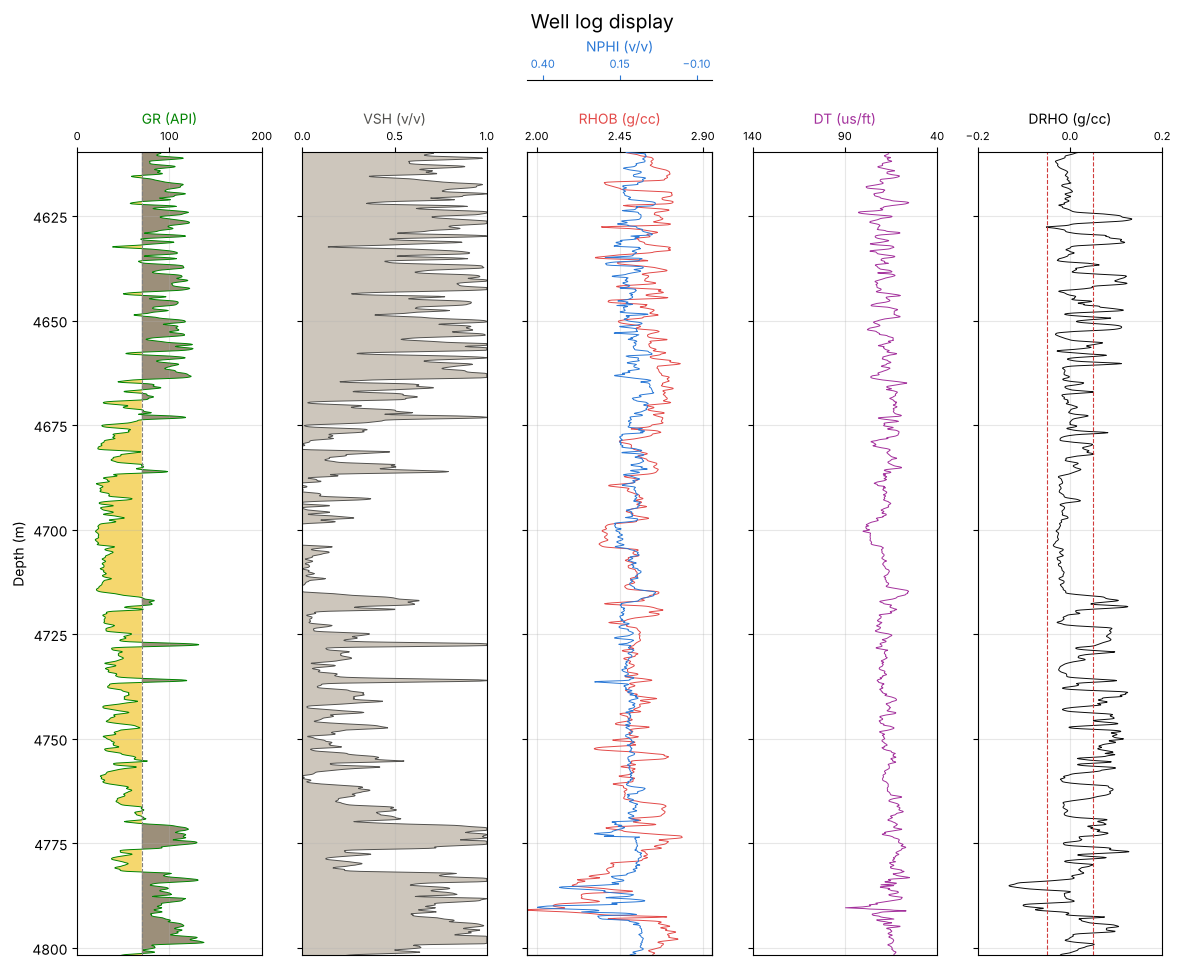

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(14, 11), sharey=True)
fig.subplots_adjust(top=0.84, wspace=0.22)

top, base = well["DEPTH"].min(), well["DEPTH"].max()
depth = well["DEPTH"]

# Track 1 - gamma ray, shaded sand and shale at the cutoff
ax = axes[0]
ax.plot(well["GR"], depth, color="#008300", lw=0.7)
ax.fill_betweenx(depth, cutoff, well["GR"], where=well["GR"] >= cutoff,
                 facecolor="#9c8f7a", interpolate=True)
ax.fill_betweenx(depth, cutoff, well["GR"], where=well["GR"] < cutoff,
                 facecolor="#f5d76e", interpolate=True)
ax.axvline(cutoff, color="grey", lw=0.8, ls="--")
ax.set_xlim(0, 200)
ax.set_xticks([0, 100, 200])
ax.set_xlabel("GR (API)", color="#008300")
ax.set_ylabel("Depth (m)")

# Track 2 - shale volume
ax = axes[1]
ax.plot(well["VSH"], depth, color="#52514e", lw=0.7)
ax.fill_betweenx(depth, 0, well["VSH"], facecolor="#9c8f7a", alpha=0.5)
ax.set_xlim(0, 1)
ax.set_xticks([0, 0.5, 1])
ax.set_xlabel("VSH (v/v)", color="#52514e")

# Track 3 - density with neutron on top
ax = axes[2]
ax.plot(well["RHOB"], depth, color="#e34948", lw=0.7)
ax.set_xlim(1.95, 2.95)
ax.set_xticks([2.0, 2.45, 2.9])
ax.set_xlabel("RHOB (g/cc)", color="#e34948")

axn = ax.twiny()
axn.plot(well["NPHI"], depth, color="#2a78d6", lw=0.7)
axn.set_xlim(0.45, -0.15)
axn.set_xticks([0.4, 0.15, -0.1])
axn.set_xlabel("NPHI (v/v)", color="#2a78d6")
axn.spines["top"].set_position(("axes", 1.09))
axn.tick_params(axis="x", labelsize=8, colors="#2a78d6")

# Track 4 - sonic
ax = axes[3]
ax.plot(well["DT"], depth, color="#a3309c", lw=0.7)
ax.set_xlim(140, 40)
ax.set_xticks([140, 90, 40])
ax.set_xlabel("DT (us/ft)", color="#a3309c")

# Track 5 - density correction (quality curve)
ax = axes[4]
ax.plot(well["DRHO"], depth, color="#0b0b0b", lw=0.7)
ax.axvline(0.05, color="#d03b3b", lw=0.8, ls="--")
ax.axvline(-0.05, color="#d03b3b", lw=0.8, ls="--")
ax.set_xlim(-0.2, 0.2)
ax.set_xticks([-0.2, 0, 0.2])
ax.set_xlabel("DRHO (g/cc)")

for ax in axes:
    ax.set_ylim(base, top)
    ax.xaxis.set_label_position("top")
    ax.xaxis.set_ticks_position("top")
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3)

fig.suptitle("Well log display", fontsize=14, y=0.97)
plt.show()

**Track 5 is the density correction.** The density tool has a pad pressed against
the borehole wall. Mudcake or a rough hole holds it off, and the tool corrects for
that gap using two detectors at different spacings. DRHO is the size of that
correction.

It describes the tool, not the rock. Where it runs past about 0.05 g/cc the pad
was not making good contact, so the density reading there is less reliable. In
this well that happens mostly below 4,740 m.

## 4. How much sand

Each sample covers 0.1 m of hole, so counting samples below the cutoff and
multiplying by 0.1 gives thickness.

In [7]:
step = 0.1

sand_samples = (well["GR"] < cutoff).sum()
sand_m = sand_samples * step
total_m = len(well) * step

print(f"Sand:  {sand_m:.1f} m")
print(f"Shale: {total_m - sand_m:.1f} m")
print(f"Total: {total_m:.1f} m")
print(f"Sand is {sand_m / total_m * 100:.0f}% of the interval")

Sand:  104.3 m
Shale: 87.8 m
Total: 192.1 m
Sand is 54% of the interval


## Notes

- The cutoff and the clean and shale values come from this well's own histogram, not from a textbook. On another well they would be read again.
- Linear shale volume reads slightly high. It is the conservative choice.
- Gamma ray is an indicator, not proof. Some clean sands contain feldspar or mica and read hot without being shale.
- There is no resistivity curve here, so nothing in this analysis says anything about oil or gas. That would need water saturation.